# Voicemail / Answering Machine Detector

**Binary classifier**: Answering Machine vs Non-Answering Machine  
**Architecture**: CNN (Mel Spectrogram)

**Author**: Zyan Bezzant (zbezzant)

# Reference

- https://librosa.org/doc/latest/generated/librosa.feature.melspectrogram.html
- https://pytorch.org/audio/stable/transforms.html#torchaudio.transforms.MelSpectrogram
- https://pytorch.org/audio/stable/transforms.html#torchaudio.transforms.AmplitudeToDB
- https://arxiv.org/abs/1609.09430
- https://arxiv.org/abs/1409.1556
- https://arxiv.org/abs/1610.02391
- https://pytorch.org/tutorials/beginner/blitz/cifar10_tutorial.html
- https://pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html
- https://pytorch.org/docs/stable/generated/torch.optim.AdamW.html
- https://pytorch.org/docs/stable/generated/torch.optim.lr_scheduler.ReduceLROnPlateau.html
- https://pytorch.org/docs/stable/generated/torch.nn.utils.clip_grad_norm_.html
- https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.classification_report.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.roc_auc_score.html
- https://scikit-learn.org/stable/modules/generated/sklearn.metrics.confusion_matrix.html
- https://www.youtube.com/watch?v=9GHCiiDLHQ4
- https://www.youtube.com/watch?v=0loVfl2Lq4s
- https://www.geeksforgeeks.org/nlp/mel-frequency-cepstral-coefficients-mfcc-for-speech-recognition/
- https://dev.to/aditi_baheti_f4a40487a091/an-in-depth-look-at-audio-classification-using-cnns-and-transformers-1981

# Abstract

Automated voicemail detection is an audio-classification problem relevant to call-handling systems. This project evaluates a convolutional neural network (CNN) trained on mel spectrograms generated from labeled voicemail and non-voicemail call recordings. The dataset contains 12,501 recordings, with 6,298 labeled as answering-machine calls and 6,203 as non-answering-machine calls. The data was divided into training, validation, and held-out test sets; the test set contains 1,876 recordings.

On the held-out test set, the model achieved **95% accuracy** and a **ROC-AUC of 0.9871**. Error analysis identified continuous speech and background noise among examples incorrectly classified as voicemails, while some voicemail recordings containing primarily a beep were classified as non-voicemails. Detecting voicemail beeps as an additional feature may be a useful direction for future work.

# Introduction

This project explores whether audio features can help distinguish answering-machine recordings from non-answering-machine calls. Rather than relying only on the words spoken, the model analyzes mel spectrograms—visual representations of audio frequency over time—to learn patterns that may help identify the two classes.

The dataset consists of call recordings labeled as answering-machine or non-answering-machine examples. Some initial labels were reviewed and corrected by hand, and additional data was labeled as the dataset grew. The final notebook reports **12,501 recordings**: **6,298 answering-machine examples** and **6,203 non-answering-machine examples**. The data was split into training, validation, and held-out test sets for model development and evaluation.

The model is a binary classifier that produces a score between 0 and 1, interpreted as the model’s estimated likelihood that a recording is an answering-machine call. With the notebook’s 0.5 threshold, scores above 0.5 are classified as answering-machine calls, and scores below 0.5 as non-answering-machine calls.

Audio may contain cues that are not captured by the words alone. For example, a voicemail greeting may include continuous speech or a tone indicating when to leave a message. Other potentially useful cues include speech rhythm and pitch patterns. This project investigates whether a CNN trained on mel spectrograms can learn useful audio patterns; explicit beep detection and other handcrafted audio features remain possible directions for future work.


# Methods

The first step is cleaning the data. The call recordings are in the .ogg audio format and the classification is in its metadata. Three cleaning steps are applied, first, the files are sorted based on if they are a voicemail or not. Second, they are converted to .wav. Third, they are shortened or lengthened to 10 seconds in length (long enough to capture voicemail indicators). Fourth, they are normalized so they are all around the same volume. Lastly, if there is a long period of silence, it is trimmed.

This model is using the CNN architecture. It analyzes the mel spectrograms of the audio recordings. A mel spectrogram is a visual representation of sound that is scaled to match human perception of sound rather than being linearly scaled. The CNN treats the spectrogram the same way it treats images. The mel spectrograms for each audio file are generated beforehand on the GPU if it has access to it. Then, the spectrograms are fed into four stacked convolutional blocks. Each has a pipeline through Conv2D, a small filter that slides around looking for patterns, whose feature map goes into the next step, which is batch normalization. This is done to balance out the many wild scales the feature map values can be in. Next, it goes through ReLU to kill the negatives. It does those all again then it goes through MaxPool which halves the spatial dimensions each time and a dropout. These steps are completed each time the data goes through one of the four convolutional bocks. After these blocks, each feature map is fed through an AdaptiveAvgPool, which forces every feature map down to a 4×4 spatial grid regardless of its incoming size.

This spatial grid is flattened into a single vector and that vector is passed through two dense layers each followed by a ReLU activation and dropout layer. The final layer collapses everything down to a logit. This is passed through a sigmoid function which gives us our final value between 0 and 1 that is our confidence that the input is a voicemail. I am using the BCEWithLogitsLoss loss function which is standard for binary classification. I am using the optimizer AdamW. The dataset gets split up into three subsets: 73% for training, 12% for validation, and 15% for testing. Validation is used during training to monitor whether or not the model is improving. Based on the early stopping patience, the training can be stopped early if the model does not improve over a set number of epochs.

## Imports

In [1]:
import os # file paths
import pickle # saving and loading valid_paths cache
import platform # detects windows for multiprocessing
import warnings # suppresses warnings
warnings.filterwarnings('ignore')

import numpy as np
import librosa # loads .wav files

import torch
import torch.nn as nn
import torch.optim as optim # adamW
import torchaudio.transforms as T # MelSpectrogram and AmplitudeToDB running in batches on GPU
from torch.utils.data import Dataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, classification_report, roc_auc_score

from tqdm import tqdm # Progress bar
import matplotlib.pyplot as plt # plotting
import seaborn as sns # confusion matrix

print(f'PyTorch : {torch.__version__}')
print(f'librosa : {librosa.__version__}')
print(f'CUDA    : {torch.cuda.is_available()}') # Requires python 3.11 for torch version 2.5.1+cu121
if torch.cuda.is_available():
    print(f'GPU     : {torch.cuda.get_device_name(0)}')
    print(f'VRAM    : {torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')

PyTorch : 2.5.1+cu121
librosa : 0.11.0
CUDA    : True
GPU     : NVIDIA GeForce RTX 3060
VRAM    : 12.9 GB


## Helpers

In [2]:
# paths
AM_PATH = r'answering_machine' # Answering machine call recordings path
NAM_PATH = r'non_answering_machine' # Non-Answering machine call recordings path
CACHE_DIR = r'cache' # cache path for the extracted features
os.makedirs(CACHE_DIR, exist_ok=True)

# Audio settings
SR = 16000 # sample rate for audio, 16kHz is standard for speech
DURATION = 10 # length in seconds of the audio clips
N_SAMPLES = SR * DURATION # sample count

# Mel Spectrogram
N_MELS = 64 # Height of spectrogram (higher means more detail)
N_FFT = 1024 # Fourier transform slice window (bigger means finer frequency detail)
HOP_LENGTH = 512 # how far the window slides between each FFT. 512 is 50% overlap with N_FFT = 1024
FMIN = 50 # lowest frequency threshold
FMAX = 8000 # lowest frequency threshold

# training
BATCH_SIZE = 32 # how many clips are processed together per gradient update
EPOCHS = 60 # maximum passes
LR = 1e-3 # Learning rate 0.001
WEIGHT_DECAY = 1e-4 # L2 regularization strength to prevent overfitting
ES_PATIENCE = 20 # early stopping patience (number of epochs with no improvement)

# device
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu') # use GPU if available
num_workers = 0 if platform.system() == 'Windows' else 4 # if windows don't use PyTorch multiprocessing
pin_memory = torch.cuda.is_available() # GPU memory speed up
print(f'Device: {device} | Workers: {num_workers}')

# GPU mel transform
mel_transform = T.MelSpectrogram( # uses settings above to process raw audio to spectrograms on GPU
    sample_rate=SR, n_fft=N_FFT, hop_length=HOP_LENGTH,
    n_mels=N_MELS, f_min=FMIN, f_max=FMAX
).to(device)

amplitude_to_db = T.AmplitudeToDB(top_db=80).to(device)

Device: cuda | Workers: 0


Each 10-second clip yields:
- **Mel spectrogram** `(1, 64, ~313)` -1 channel, 64 frequency bins tall, 313 time frames wide- to CNN branch

In [3]:
def compute_mel_gpu(file_paths, batch_size=64): # converts a list of .wav files into a stack of normalized mel spectrograms using the GPU
    mel_list = []

    for i in tqdm(range(0, len(file_paths), batch_size), desc='GPU Mel  '):
        batch_paths = file_paths[i:i + batch_size] # creates batches
        batch_audio = []

        for path in batch_paths:
            y, _ = librosa.load(path, sr=SR, mono=True)
            if len(y) < N_SAMPLES:
                y = np.pad(y, (0, N_SAMPLES - len(y)), mode='constant')
            else:
                y = y[:N_SAMPLES]
            batch_audio.append(y) # standardizes the audio, making it mono and uniform length

        batch_t = torch.from_numpy(
            np.array(batch_audio, dtype=np.float32)
        ).to(device) # sending batches to the GPU

        with torch.no_grad():
            mel = mel_transform(batch_t) # generate the mel spectrograms
            mel = amplitude_to_db(mel) # standardize

        mel_np = mel.cpu().numpy()

        for m in mel_np: # normalize all the spectrograms
            m_norm = ((m - m.min()) / (m.max() - m.min() + 1e-8)).astype(np.float32)
            mel_list.append(m_norm)

    return np.array(mel_list, dtype=np.float32)


def build_dataset(am_path, nam_path, cache_dir): # saves and loads processed data
    # checks if cache (mel spectrograms) already exists
    cache_mel = os.path.join(cache_dir, 'mel_specs.npy')
    cache_lbl = os.path.join(cache_dir, 'labels.npy')

    if all(os.path.exists(p) for p in [cache_mel, cache_lbl]):
        print('Loading cached features...')
        with open(os.path.join(cache_dir, 'valid_paths.pkl'), 'rb') as f: # valid_paths.pkl is for the false positives table
            valid_paths = pickle.load(f)
        return np.load(cache_mel), np.load(cache_lbl), valid_paths

    # Scans for the .wav files and labels them as 1 for voicemail or 0 for non-voicemail
    am_files = sorted([os.path.join(am_path,  f)
                        for f in os.listdir(am_path)  if f.lower().endswith('.wav')])
    nam_files = sorted([os.path.join(nam_path, f)
                        for f in os.listdir(nam_path) if f.lower().endswith('.wav')])
    all_files = [(f, 1) for f in am_files] + [(f, 0) for f in nam_files]
    paths = [f for f, _ in all_files]
    lbls = [l for _, l in all_files]

    print(f'AM: {len(am_files)}  |  Non-AM: {len(nam_files)}')

    # Sends all the recordings to the GPU to be spectrogamiterized.
    print(f'\nMel spectrograms (GPU batch={64})...')
    mel_arr = compute_mel_gpu(paths, batch_size=64)
    lbl_arr = np.array(lbls, dtype=np.float32)

    # Saves to cache so they can be reused.
    np.save(cache_mel, mel_arr)
    np.save(cache_lbl, lbl_arr)
    with open(os.path.join(cache_dir, 'valid_paths.pkl'), 'wb') as f:
        pickle.dump(paths, f)
    print(f'\nCached to {cache_dir}')

    return mel_arr, lbl_arr, paths


mel_specs, labels, valid_paths = build_dataset(AM_PATH, NAM_PATH, CACHE_DIR) # build dataset.

print(f'\nMel spectrogram shape : {mel_specs.shape}')
print(f'Labels                : {labels.shape}')
print(f'AM={int(labels.sum())}  Non-AM={int((1-labels).sum())}')

Loading cached features...

Mel spectrogram shape : (12436, 64, 313)
Labels                : (12436,)
AM=6249  Non-AM=6187


## Dataset & DataLoaders

In [4]:
# wrapper class as Dataset object for PyTorch
class VoicemailDataset(Dataset):
    def __init__(self, mel, labels):
        # mel has N (batch), freq, time. add channel dimension N, 1 (monochrome), freq, time
        self.mel = torch.from_numpy(mel).unsqueeze(1)
        self.labels = torch.from_numpy(labels) # tensor

    def __len__(self):  return len(self.labels)

    def __getitem__(self, idx):
        return self.mel[idx], self.labels[idx]

# Break up data into subsets
idx = np.arange(len(labels))
train_idx, test_idx = train_test_split(idx, test_size=0.15, # 15% to testing
                                       stratify=labels, random_state=42)
train_idx, val_idx = train_test_split(train_idx, test_size=0.12, # 12% to validation
                                       stratify=labels[train_idx], random_state=42)

train_ds = VoicemailDataset(mel_specs[train_idx], labels[train_idx])
val_ds = VoicemailDataset(mel_specs[val_idx],   labels[val_idx])
test_ds = VoicemailDataset(mel_specs[test_idx],  labels[test_idx])

# Dataloaders serve the data to the model for training, testing, and validation.
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,
                          num_workers=num_workers, pin_memory=pin_memory)
val_loader = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=num_workers, pin_memory=pin_memory)
test_loader = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False,
                          num_workers=num_workers, pin_memory=pin_memory)

print(f'Train: {len(train_ds)} | Val: {len(val_ds)} | Test: {len(test_ds)}')

Train: 9301 | Val: 1269 | Test: 1866


## Model Architecture

```
Mel (1, 64, 313)
│
CNNBlock ×4 -- 2× (Conv2D to BatchNorm to ReLU) to MaxPool to Dropout
│
AdaptiveAvgPool(4,4)
│
Flatten to Dense(256) + ReLU + Dropout
│
Dense(128) + ReLU + Dropout
│
Dense(1) to logit
```
Uses `BCEWithLogitsLoss` (numerically stable — no sigmoid inside the model).

In [5]:
class CNNBlock(nn.Module):
    # 2x (Conv to BN to ReLU) + MaxPool + Dropout
    def __init__(self, in_ch, out_ch):
        super().__init__()
        self.block = nn.Sequential(
            nn.Conv2d(in_ch,  out_ch, 3, padding=1, bias=False), # slides around looking for patterns 2d Convolutional Layer
            nn.BatchNorm2d(out_ch), # normalizes the feature maps
            nn.ReLU(inplace=True), # kill the negative
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False), # repeat to refine the features stacking small filters
            nn.BatchNorm2d(out_ch),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2), # halves the detail forcing stronger activations to stay
            nn.Dropout2d(0.2), # 20% dropout
        )
    def forward(self, x): return self.block(x)


class VoicemailNet(nn.Module):
    def __init__(self):
        super().__init__()

        # CNN branch (mel spectrogram)
        self.cnn = nn.Sequential(
            # 4 CNNBlocks stacked shrinking the spatial size and increasing the features (flattening)
            CNNBlock(1,   32),
            CNNBlock(32,  64),
            CNNBlock(64,  128),
            CNNBlock(128, 256),
            nn.AdaptiveAvgPool2d((4, 4)),  # fixed output regardless of time length (adaptive)
        )
        self.classifier = nn.Sequential(
            nn.Flatten(), # unrolls the remaining features to a list
            nn.Linear(256 * 4 * 4, 256), # first dense layer
            nn.ReLU(), # kills negatives
            nn.Dropout(0.4), # 40% dropout
            nn.Linear(256, 128), # second dense layer
            nn.ReLU(),
            nn.Dropout(0.3), # 30% dropout
            nn.Linear(128, 1) # final layer collapse to logit
        )

    def forward(self, mel):
        return self.classifier(self.cnn(mel)).squeeze(1) # removes trailing N (batch) dimension


model = VoicemailNet().to(device)

# Count parameters
total = sum(p.numel() for p in model.parameters())
trainp = sum(p.numel() for p in model.parameters() if p.requires_grad)
print(f'Total parameters    : {total:,}')
print(f'Trainable parameters: {trainp:,}')

Total parameters    : 2,254,497
Trainable parameters: 2,254,497


## Training

In [6]:
# Standard binary loss function using logits
criterion = nn.BCEWithLogitsLoss()
# everyone's favorite AdamW
optimizer = optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY) # Weight decay is a penalty for large weights
# dynamically halves learning rates if improvement slows
scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer, mode='min', patience=6, factor=0.5)

# Handles one full pass through the dataset
def run_epoch(model, loader, optimizer, criterion, device, training=True):
    model.train() if training else model.eval() # starts .train mode if in training to enable batchnorm and dropout
    total_loss, correct, total = 0.0, 0, 0

    ctx = torch.enable_grad() if training else torch.no_grad() # evaluation doesn't need gradients
    with ctx:
        for mel, labels in loader:
            mel, labels = mel.to(device), labels.to(device) # moves data to GPU
            if training:
                optimizer.zero_grad() # clears gradients from previous batch
            # foward pass
            logits = model(mel)
            loss = criterion(logits, labels)

            if training:
                loss.backward() # backprop
                nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0) # gradient clipping
                optimizer.step() # updates weights

            # tracking metrics
            total_loss += loss.item()
            preds = (torch.sigmoid(logits) > 0.5).float() # sigmoid at the very end.
            correct += (preds == labels).sum().item()
            total += labels.size(0)

    return total_loss / len(loader), correct / total # returns average loss per batch and overall accuracy

In [7]:
if torch.cuda.is_available():
    torch.cuda.empty_cache() # frees GPU memory

history = {'train_loss': [], 'val_loss': [], 'train_acc': [], 'val_acc': []} # instantiates history
best_val_loss = float('inf') # tracks lowest validation loss value
best_model_path = os.path.join(CACHE_DIR, 'best_model.pt') # saves that top model
no_improve = 0 # counts up to the patience limit

print(f'Training on {device} — up to {EPOCHS} epochs (early stop patience={ES_PATIENCE})\n')

for epoch in range(1, EPOCHS + 1):
    # One training pass (updates weights)
    t_loss, t_acc = run_epoch(model, train_loader, optimizer,
                              criterion, device, training=True)
    # One validation pass
    v_loss, v_acc = run_epoch(model, val_loader, optimizer,
                              criterion, device, training=False)

    # Scheduler decides whether to lower the learning rate
    scheduler.step(v_loss)

    # logs metrics
    history['train_loss'].append(t_loss)
    history['val_loss'].append(v_loss)
    history['train_acc'].append(t_acc)
    history['val_acc'].append(v_acc)

    # records the best model combination so far
    if v_loss < best_val_loss:
        best_val_loss = v_loss
        torch.save(model.state_dict(), best_model_path)
        no_improve = 0
        marker = ' saved'
    else:
        no_improve += 1
        marker = ''

    if epoch % 5 == 0 or epoch == 1 or marker:
        print(f'Epoch {epoch:3d}/{EPOCHS}  '
              f'Train  loss={t_loss:.4f}  acc={t_acc:.3f}  |  '
              f'Val  loss={v_loss:.4f}  acc={v_acc:.3f}{marker}')

    # stop if no improvements once patience is up
    if no_improve >= ES_PATIENCE:
        print(f'\nEarly stopping at epoch {epoch} (no improvement for {ES_PATIENCE} epochs)')
        break

print(f'\nBest val loss: {best_val_loss:.4f}')


Training on cuda — up to 60 epochs (early stop patience=20)

Epoch   1/60  Train  loss=0.4692  acc=0.797  |  Val  loss=0.3554  acc=0.857 saved
Epoch   2/60  Train  loss=0.3860  acc=0.843  |  Val  loss=0.3476  acc=0.865 saved
Epoch   5/60  Train  loss=0.3357  acc=0.868  |  Val  loss=0.3240  acc=0.872 saved
Epoch   7/60  Train  loss=0.3146  acc=0.877  |  Val  loss=0.2923  acc=0.886 saved
Epoch   8/60  Train  loss=0.3023  acc=0.883  |  Val  loss=0.2899  acc=0.884 saved
Epoch   9/60  Train  loss=0.2887  acc=0.887  |  Val  loss=0.2764  acc=0.883 saved
Epoch  10/60  Train  loss=0.2757  acc=0.893  |  Val  loss=0.2761  acc=0.899 saved
Epoch  11/60  Train  loss=0.2593  acc=0.901  |  Val  loss=0.2522  acc=0.904 saved
Epoch  12/60  Train  loss=0.2518  acc=0.905  |  Val  loss=0.2410  acc=0.904 saved
Epoch  15/60  Train  loss=0.2167  acc=0.917  |  Val  loss=0.2168  acc=0.910 saved
Epoch  20/60  Train  loss=0.1940  acc=0.926  |  Val  loss=0.2129  acc=0.913 saved
Epoch  25/60  Train  loss=0.1609  acc

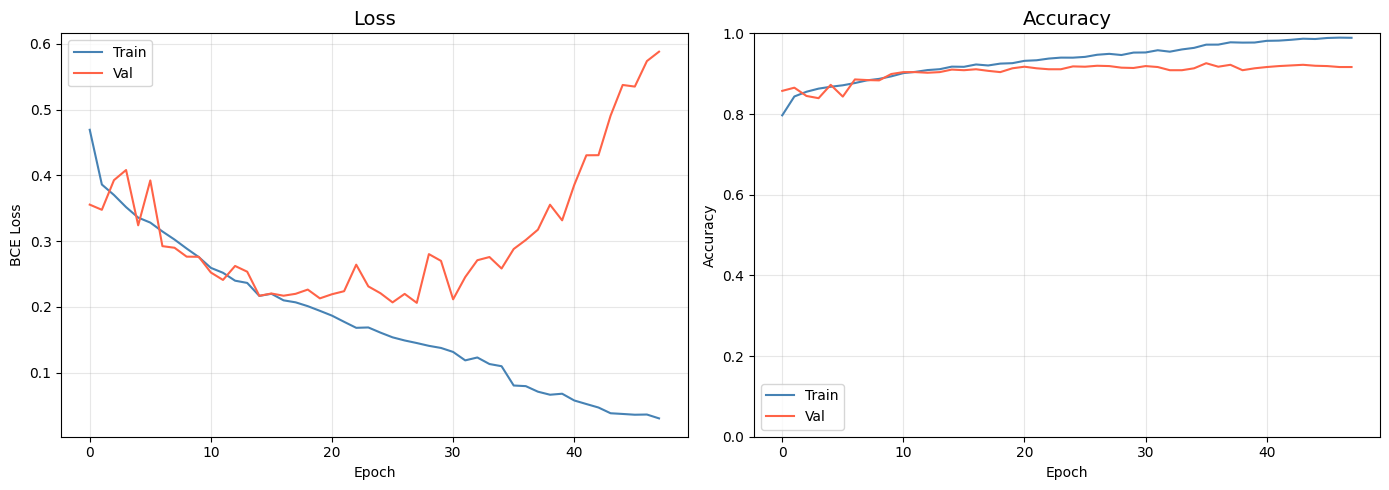

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].plot(history['train_loss'], label='Train', color='steelblue')
axes[0].plot(history['val_loss'],   label='Val',   color='tomato')
axes[0].set_title('Loss', fontsize=14)
axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('BCE Loss')
axes[0].legend(); axes[0].grid(alpha=0.3)

axes[1].plot(history['train_acc'], label='Train', color='steelblue')
axes[1].plot(history['val_acc'],   label='Val',   color='tomato')
axes[1].set_title('Accuracy', fontsize=14)
axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Accuracy')
axes[1].set_ylim(0, 1); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, 'training_history.png'), dpi=150)
plt.show()


## Evaluation on Held-Out Test Set and Confusion Matrix

TEST SET RESULTS
                   precision    recall  f1-score   support

           Non-AM       0.95      0.90      0.93       928
Answering Machine       0.91      0.95      0.93       938

         accuracy                           0.93      1866
        macro avg       0.93      0.93      0.93      1866
     weighted avg       0.93      0.93      0.93      1866

ROC-AUC : 0.9762


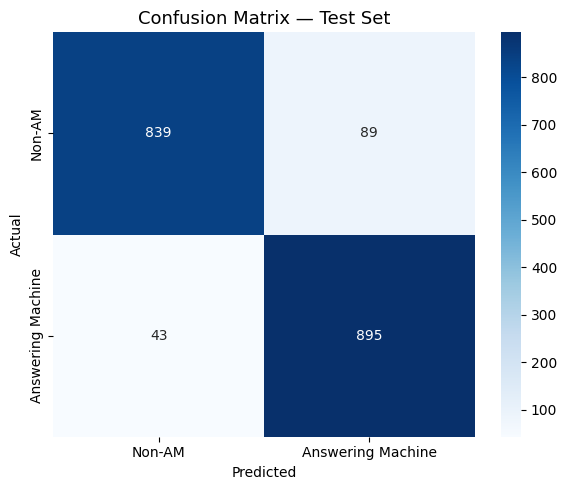

In [9]:
# Load best checkpoint
model.load_state_dict(torch.load(best_model_path, map_location=device, weights_only=True))
model.eval() # disables dropout and batchnorm

all_preds, all_probs, all_labels = [], [], [] # accumulators

# tests data and converts it to usable numpy
with torch.no_grad():
    for mel, lbls in test_loader:
        logits = model(mel.to(device))
        probs = torch.sigmoid(logits).cpu().numpy()
        preds = (probs > 0.5).astype(int)
        all_probs.extend(probs.tolist())
        all_preds.extend(preds.tolist())
        all_labels.extend(lbls.numpy().astype(int).tolist())

print('=' * 55)
print('TEST SET RESULTS')
print('=' * 55)
print(classification_report(all_labels, all_preds,
                             target_names=['Non-AM', 'Answering Machine']))
print(f'ROC-AUC : {roc_auc_score(all_labels, all_probs):.4f}')

# Confusion matrix
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Non-AM', 'Answering Machine'],
            yticklabels=['Non-AM', 'Answering Machine'])
plt.title('Confusion Matrix — Test Set', fontsize=13)
plt.ylabel('Actual'); plt.xlabel('Predicted')
plt.tight_layout()
plt.savefig(os.path.join(CACHE_DIR, 'confusion_matrix.png'), dpi=150)
plt.show()


## Spectrogram Visualization

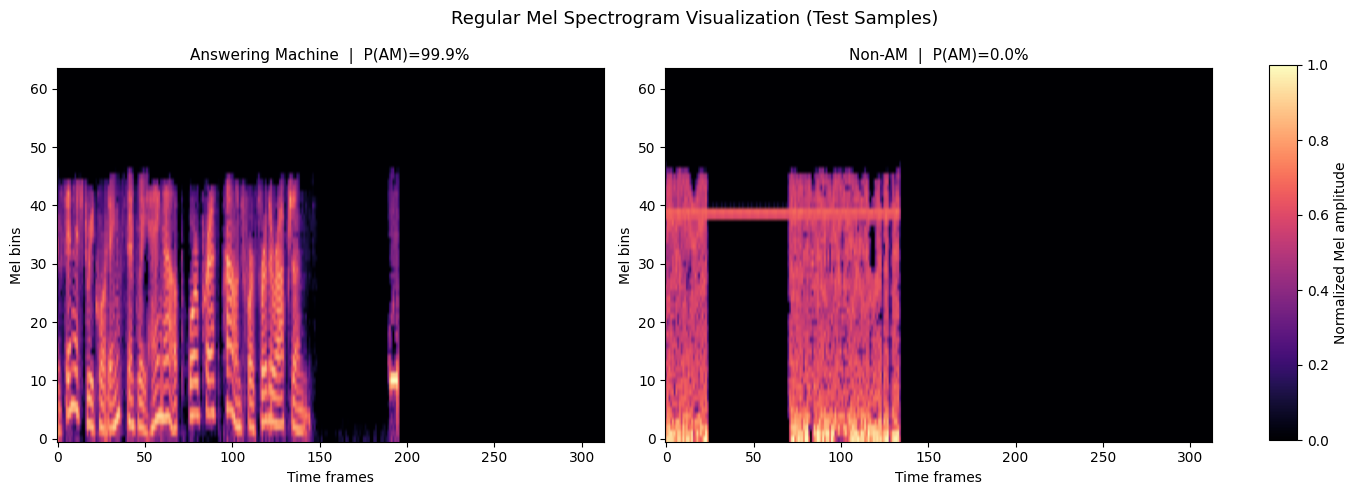

In [10]:
am_idx = next(i for i, l in enumerate(all_labels) if l == 1)
nam_idx = next(i for i, l in enumerate(all_labels) if l == 0)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, idx, title in [
    (axes[0], am_idx, f'Answering Machine  |  P(AM)={all_probs[am_idx]:.1%}'),
    (axes[1], nam_idx, f'Non-AM  |  P(AM)={all_probs[nam_idx]:.1%}')
]:
    mel_t, _ = test_ds[idx]
    mel_np = mel_t.squeeze(0).cpu().numpy()
    im = ax.imshow(mel_np, aspect='auto', origin='lower', cmap='magma')
    ax.set_title(title, fontsize=11)
    ax.set_xlabel('Time frames')
    ax.set_ylabel('Mel bins')

plt.subplots_adjust(right=0.88)
cbar_ax = fig.add_axes([0.91, 0.12, 0.02, 0.75])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label('Normalized Mel amplitude')

plt.suptitle('Regular Mel Spectrogram Visualization (Test Samples)', fontsize=13)
plt.tight_layout(rect=[0, 0, 0.88, 1])
plt.savefig(os.path.join(CACHE_DIR, 'mel_regular_visualization.png'), dpi=150, bbox_inches='tight')
plt.show()


## False Positives and Negatives

PAI_2026-05-11_13-08-08_FIVESTRATA-006_9008-P1.wav FP
PAI_2026-05-07_11-47-40_FIVESTRATA-015_9017-P1.wav FP
PAI_2026-05-05_15-58-07_FIVESTRATA-004_9006-P1.wav FP
PAI_2026-05-07_10-42-11_FIVESTRATA-006_9008-P1.wav FP
PAI_2026-05-11_11-23-49_FIVESTRATA-005_9007-P1.wav FP
PAI_2026-05-11_16-36-19_FIVESTRATA-008_9010-P1.wav FN
PAI_2026-05-05_10-23-10_FIVESTRATA-013_9015-P1.wav FN
PAI_2026-05-11_12-56-03_FIVESTRATA-021_9023-P1.wav FN
PAI_2026-05-05_15-30-39_FIVESTRATA-005_9007-P1.wav FN
PAI_2026-05-07_10-52-35_FIVESTRATA-017_9019-P1.wav FN


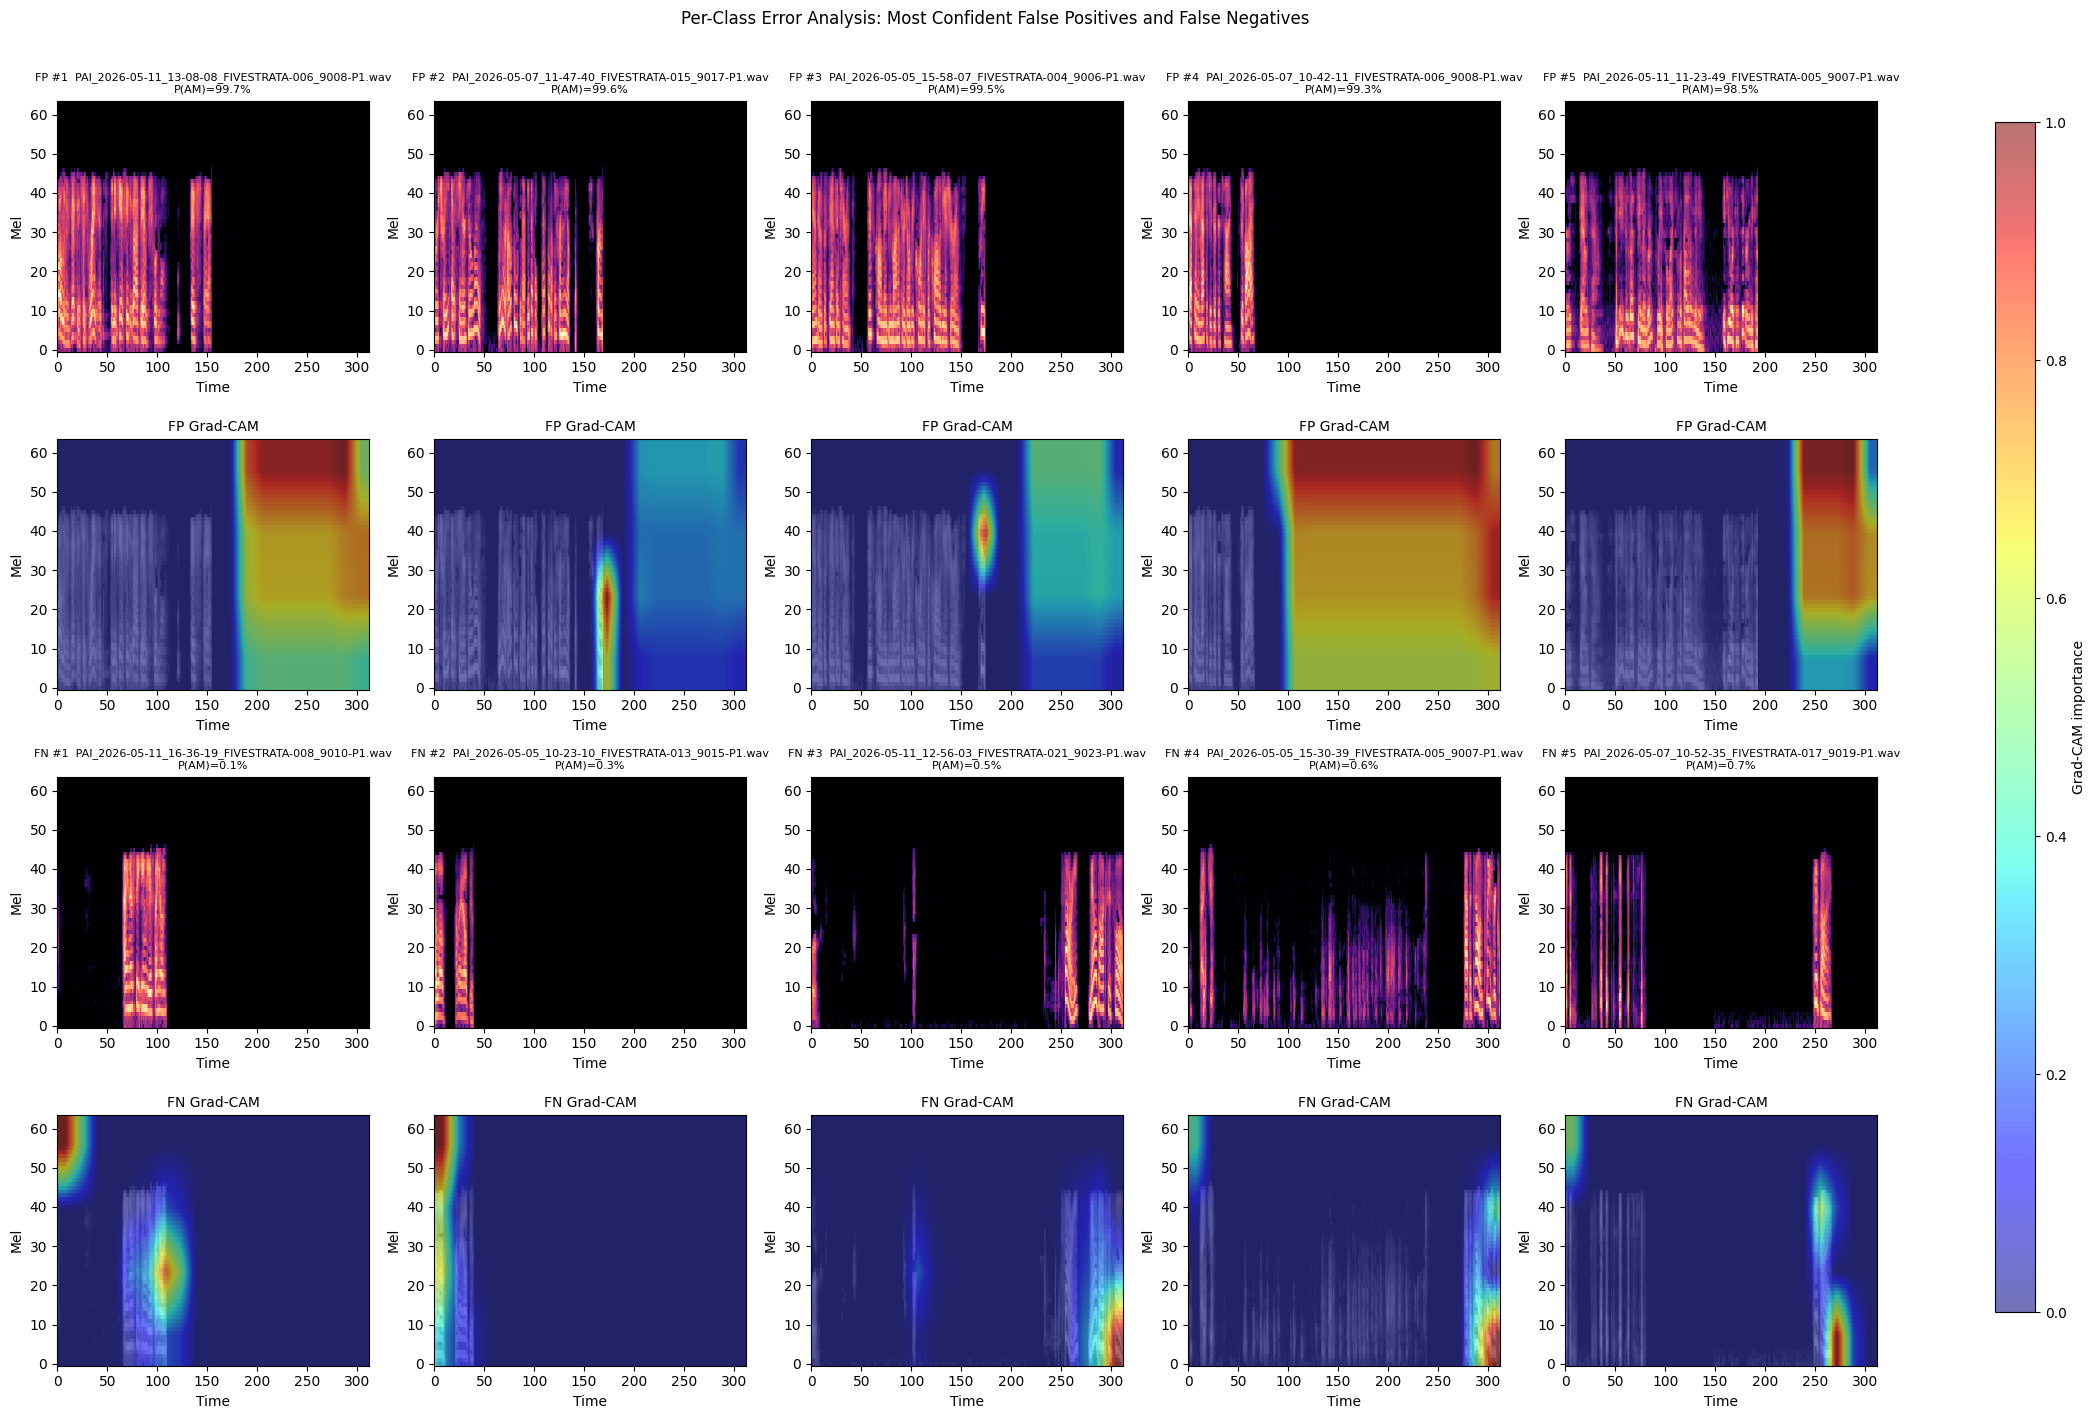

In [11]:
import torch.nn.functional as F

def compute_gradcam(model, mel_tensor, block_idx=3):
    saved_act, saved_grad = [], []

    def fwd_hook(m, inp, out):
        saved_act.append(out.detach())

    def bwd_hook(m, gi, go):
        saved_grad.append(go[0].detach())

    target = model.cnn[block_idx]
    h1 = target.register_forward_hook(fwd_hook)
    h2 = target.register_full_backward_hook(bwd_hook)

    logit = model(mel_tensor.clone().requires_grad_(True))
    model.zero_grad()
    logit.backward()

    h1.remove()
    h2.remove()

    act = saved_act[0][0].cpu().numpy()
    grad = saved_grad[0][0].cpu().numpy()
    weights = grad.mean(axis=(1, 2))

    cam = np.einsum('c,chw->hw', weights, act)
    cam = np.maximum(cam, 0)
    if cam.max() > 0:
        cam /= cam.max()
    return cam

model.eval()

labels_arr = np.array(all_labels).astype(int)
preds_arr = np.array(all_preds).astype(int)
probs_arr = np.array(all_probs, dtype=np.float32)

fp_idx = np.where((labels_arr == 0) & (preds_arr == 1))[0]
fn_idx = np.where((labels_arr == 1) & (preds_arr == 0))[0]

fp_conf = probs_arr[fp_idx]
fn_conf = 1.0 - probs_arr[fn_idx]

top_k = 5
top_fp = fp_idx[np.argsort(fp_conf)[::-1][:top_k]]
top_fn = fn_idx[np.argsort(fn_conf)[::-1][:top_k]]

test_paths = [valid_paths[i] for i in test_idx]

# import shutil
# FP_DIR = os.path.join(CACHE_DIR, 'FP')
# FN_DIR = os.path.join(CACHE_DIR, 'FN')
# os.makedirs(FP_DIR, exist_ok=True)
# os.makedirs(FN_DIR, exist_ok=True)
# for idx in fp_idx:
#     shutil.copy2(test_paths[idx], FP_DIR)
# for idx in fn_idx:
#     shutil.copy2(test_paths[idx], FN_DIR)
# print(f'Copied {len(fp_idx)} FP files to {FP_DIR}')
# print(f'Copied {len(fn_idx)} FN files to {FN_DIR}')

k = min(top_k, len(top_fp), len(top_fn))
if k == 0:
    print('No misclassifications available for this plot.')
else:
    top_fp = top_fp[:k]
    top_fn = top_fn[:k]

    fig, axes = plt.subplots(4, k, figsize=(4 * k, 14))

    for col, idx in enumerate(top_fp):
        mel_t, _ = test_ds[idx]
        mel_tensor = mel_t.unsqueeze(0).to(device)
        mel_np = mel_t.squeeze(0).cpu().numpy()

        cam = compute_gradcam(model, mel_tensor, block_idx=3)
        cam_up = F.interpolate(
            torch.from_numpy(cam).unsqueeze(0).unsqueeze(0),
            size=mel_np.shape,
            mode='bilinear',
            align_corners=False
        ).squeeze().numpy()

        axes[0, col].imshow(mel_np, aspect='auto', origin='lower', cmap='magma')
        axes[0, col].set_title(f'FP #{col+1}  {os.path.basename(test_paths[idx])}\nP(AM)={probs_arr[idx]:.1%}', fontsize=8)
        print(f'{os.path.basename(test_paths[idx])} FP')
        axes[0, col].set_xlabel('Time')
        axes[0, col].set_ylabel('Mel')

        axes[1, col].imshow(mel_np, aspect='auto', origin='lower', cmap='gray', alpha=0.7)
        axes[1, col].imshow(cam_up, aspect='auto', origin='lower', cmap='jet', alpha=0.55, vmin=0, vmax=1)
        axes[1, col].set_title('FP Grad-CAM', fontsize=10)
        axes[1, col].set_xlabel('Time')
        axes[1, col].set_ylabel('Mel')

    for col, idx in enumerate(top_fn):
        mel_t, _ = test_ds[idx]
        mel_tensor = mel_t.unsqueeze(0).to(device)
        mel_np = mel_t.squeeze(0).cpu().numpy()

        cam = compute_gradcam(model, mel_tensor, block_idx=3)
        cam_up = F.interpolate(
            torch.from_numpy(cam).unsqueeze(0).unsqueeze(0),
            size=mel_np.shape,
            mode='bilinear',
            align_corners=False
        ).squeeze().numpy()

        axes[2, col].imshow(mel_np, aspect='auto', origin='lower', cmap='magma')
        axes[2, col].set_title(f'FN #{col+1}  {os.path.basename(test_paths[idx])}\nP(AM)={probs_arr[idx]:.1%}', fontsize=8)
        print(f'{os.path.basename(test_paths[idx])} FN')
        axes[2, col].set_xlabel('Time')
        axes[2, col].set_ylabel('Mel')

        axes[3, col].imshow(mel_np, aspect='auto', origin='lower', cmap='gray', alpha=0.7)
        im = axes[3, col].imshow(cam_up, aspect='auto', origin='lower', cmap='jet', alpha=0.55, vmin=0, vmax=1)
        axes[3, col].set_title('FN Grad-CAM', fontsize=10)
        axes[3, col].set_xlabel('Time')
        axes[3, col].set_ylabel('Mel')

    plt.subplots_adjust(right=0.88)
    cbar_ax = fig.add_axes([1, 0.08, 0.02, 0.85]) # [left, bottom, width, height]
    cbar = fig.colorbar(im, cax=cbar_ax)
    cbar.set_label('Grad-CAM importance')

    plt.suptitle('Per-Class Error Analysis: Most Confident False Positives and False Negatives', fontsize=12, y=1.01)
    plt.tight_layout(rect=[0, 0, 0.95, 1])
    plt.savefig(os.path.join(CACHE_DIR, 'error_analysis_top_confident_mistakes.png'), dpi=150, bbox_inches='tight')
    plt.show()

## Results and Discussion

On the held-out test set of 1,876 recordings, the model achieved **95% accuracy** and a **ROC-AUC of 0.9871**. The classification report shows similar F1 scores for both classes: 0.94 for non-answering-machine calls and 0.95 for answering-machine calls.

The notebook also includes mel spectrogram visualizations and a Grad-CAM-based review of selected high-confidence false positives and false negatives. In the reviewed examples, some non-voicemail calls with continuous speech or loud background noise were classified as answering-machine calls. Some voicemail recordings containing mainly the “start recording” beep were classified as non-answering-machine calls. These examples suggest that the model may learn useful patterns from continuous speech, but can miss voicemail cues when a recording contains little spoken greeting.

These observations are based on the examples reviewed in this run; they do not establish that those patterns explain all model errors.

### Conclusions

This project demonstrates a CNN-based approach to classifying voicemail and non-voicemail audio from mel spectrograms. In the recorded run, the model achieved **95% accuracy** and a **ROC-AUC of 0.9871** on the held-out test set. These results apply to this dataset and split and should not be taken as a guarantee of performance on other recordings.

A possible next step is to investigate explicit voicemail-beep detection as an additional feature, particularly for recordings where the beep is more prominent than the greeting. Further evaluation on new, independently collected data could also help assess how well the model generalizes.

In [12]:
def predict(file_path, threshold=0.5):
    model.eval()

    y, _ = librosa.load(file_path, sr=SR, mono=True)
    if len(y) < N_SAMPLES:
        y = np.pad(y, (0, N_SAMPLES - len(y)), mode='constant')
    else:
        y = y[:N_SAMPLES]

    y_t = torch.from_numpy(y.astype(np.float32)).unsqueeze(0).to(device)
    with torch.no_grad():
        mel = amplitude_to_db(mel_transform(y_t))
    mel_np   = mel.squeeze(0).cpu().numpy()
    mel_norm = ((mel_np - mel_np.min()) / (mel_np.max() - mel_np.min() + 1e-8)).astype(np.float32)
    mel_t    = torch.from_numpy(mel_norm).unsqueeze(0).unsqueeze(0).to(device)

    with torch.no_grad():
        prob = torch.sigmoid(model(mel_t)).item()

    label = 'answering_machine' if prob >= threshold else 'non_answering_machine'
    return label, prob, 'model'

In [15]:

from tqdm import tqdm
import shutil
from pathlib import Path

# ── Config ────────────────────────────────────────────────────────────────────
INPUT_DIR   = r"hand_picked_non_voicemails"  # ← change me
OUTPUT_ROOT = r"analysis"     # ← change me
THRESHOLD   = 0.50   # probability cutoff for voicemail
MOVE_FILES  = False # True = move, False = copy

# ── Setup output dirs ─────────────────────────────────────────────────────────
voicemail_dir     = Path(OUTPUT_ROOT) / 'AIFoundVoicemails'
not_voicemail_dir = Path(OUTPUT_ROOT) / 'AINotVoicemails'
voicemail_dir.mkdir(parents=True, exist_ok=True)
not_voicemail_dir.mkdir(parents=True, exist_ok=True)

# Create 10 confidence bucket folders (0-10, 10-20, ..., 90-100)
confidence_dirs = {}
for i in range(10):
    low, high = i * 10, (i + 1) * 10
    folder_name = f'confidence_{low:02d}-{high:02d}'
    conf_dir = Path(OUTPUT_ROOT) / folder_name
    conf_dir.mkdir(parents=True, exist_ok=True)
    confidence_dirs[(low, high)] = conf_dir

# ── Sort ──────────────────────────────────────────────────────────────────────
wav_files = sorted(Path(INPUT_DIR).glob('*.wav'))
print(f'Found {len(wav_files)} .wav files\n')

results = {'answering_machine': 0, 'non_answering_machine': 0, 'error': 0}

for wav in tqdm(wav_files, desc='Sorting'):
    try:
        label, prob, source = predict(str(wav), threshold=THRESHOLD)

        dest_dir = voicemail_dir if label == 'answering_machine' else not_voicemail_dir
        dest     = dest_dir / wav.name

        if MOVE_FILES:
            shutil.move(str(wav), dest)
        else:
            shutil.copy2(str(wav), dest)

        # Also copy/move into the appropriate confidence bucket folder
        pct = int(prob * 100)
        bucket = min(pct // 10, 9)  # clamp 100% into the 90-100 bucket
        low, high = bucket * 10, (bucket + 1) * 10
        conf_dest = confidence_dirs[(low, high)] / wav.name
        if MOVE_FILES:
            shutil.copy2(dest, conf_dest)   # file already moved; copy from dest
        else:
            shutil.copy2(str(wav), conf_dest)

        results[label] += 1

    except Exception as e:
        print(f'  ERROR {wav.name}: {e}')
        results['error'] += 1

# ── Summary ───────────────────────────────────────────────────────────────────
total = len(wav_files)
print(f'\n{"─"*40}')
print(f'  AIFoundVoicemails   : {results["answering_machine"]:>5}  ({results["answering_machine"]/total:.1%})')
print(f'  AINotVoicemails     : {results["non_answering_machine"]:>5}  ({results["non_answering_machine"]/total:.1%})')
print(f'  Errors              : {results["error"]:>5}')
print(f'{"─"*40}')
print(f'  Total processed     : {total}')

Found 2007 .wav files



Sorting: 100%|██████████| 2007/2007 [00:24<00:00, 82.10it/s] 


────────────────────────────────────────
  AIFoundVoicemails   :   387  (19.3%)
  AINotVoicemails     :  1620  (80.7%)
  Errors              :     0
────────────────────────────────────────
  Total processed     : 2007
